# Part 1.1: Coverage and data quality

Before any modeling, what does the panel actually contain? This notebook answers four questions:

1. Which variables exist in which years, and where are the gaps?
2. Which known breaks and incomplete years must every later model respect?
3. Are the values plausible?
4. How much usable sample is left once the forecasting features are lagged?

The panel comes from `src/build_panel.py` (51 states, 2010 to 2025). Every column is documented in
`data/processed/panel_dictionary.csv`.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from viz import apply_style, SEQUENTIAL, SERIES, save_figure, SURFACE, INK_2
from features import FEATURE_SETS, make_supervised

apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
dic = pd.read_csv("data/processed/panel_dictionary.csv")
print(f"panel: {panel.shape[0]} rows ({panel.state_fips.nunique()} states x {panel.year.nunique()} years), {panel.shape[1]} columns")

Matplotlib is building the font cache; this may take a moment.


panel: 816 rows (51 states x 16 years), 157 columns


## What is in the panel

Columns by source. "derived" columns are computed from the others (growth rates, per-capita rates).

In [2]:
by_source = dic.groupby("source").size().rename("columns").sort_values(ascending=False).to_frame()
display(by_source)

,columns
source,
ACS 1-year,32
derived,24
HUD CHAS,20
HUD Picture of Subsidized Households,13
HUD AHAR PIT,10
HUD FMR,8
"ACS 1-year, derived",8
Census BPS,7
HUD LIHTC,7


## Coverage: which variables exist in which years

Each cell is the share of the 51 states with a value. The ACS columns are empty in 2020 (no 1-year release)
and 2025 (not yet released). The CHAS columns appear only in the end year of each five-year window. BEA price
parities, the AHAR counts, and cumulative LIHTC end before 2025.

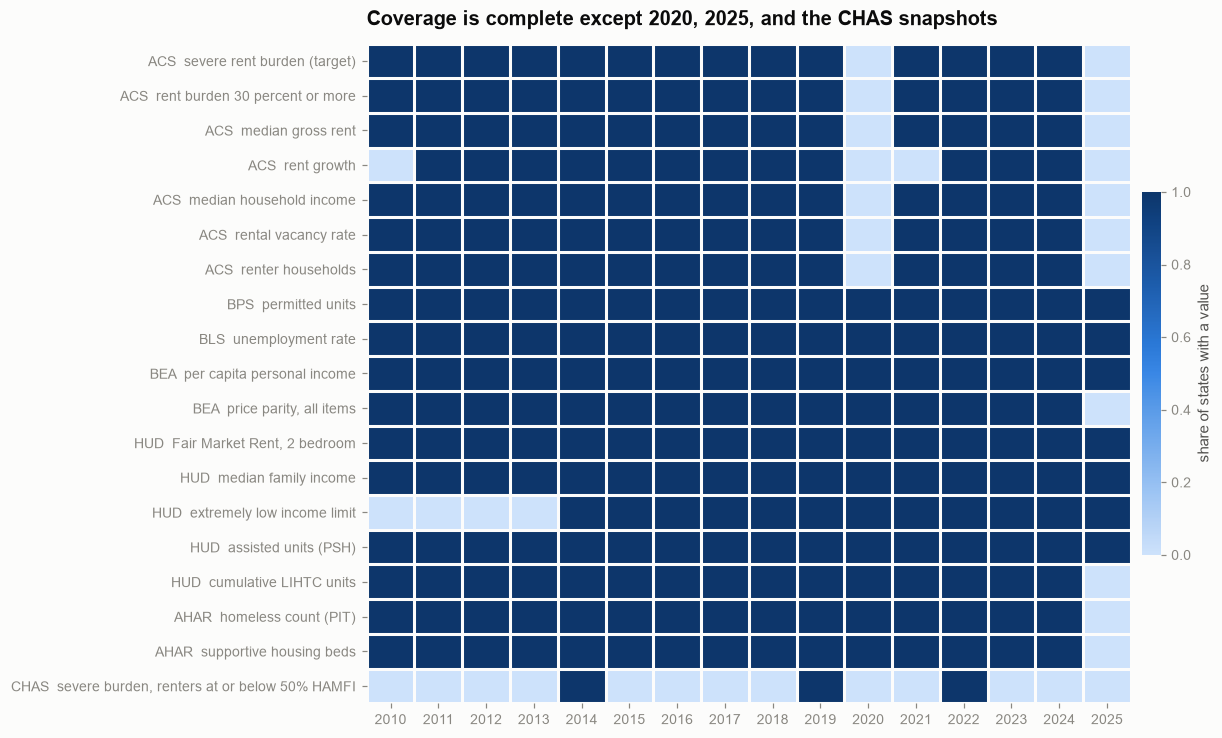

In [3]:
rows = [
    ("severe_rent_burden_pct", "ACS  severe rent burden (target)"),
    ("rent_burden_30_pct", "ACS  rent burden 30 percent or more"),
    ("median_gross_rent", "ACS  median gross rent"),
    ("rent_growth_pct", "ACS  rent growth"),
    ("median_hh_income", "ACS  median household income"),
    ("rental_vacancy_rate_pct", "ACS  rental vacancy rate"),
    ("hh_renter", "ACS  renter households"),
    ("permits_total", "BPS  permitted units"),
    ("unemployment_rate_pct", "BLS  unemployment rate"),
    ("per_capita_personal_income", "BEA  per capita personal income"),
    ("rpp_all_items", "BEA  price parity, all items"),
    ("fmr_2br", "HUD  Fair Market Rent, 2 bedroom"),
    ("hud_median_family_income", "HUD  median family income"),
    ("il_eli_4p", "HUD  extremely low income limit"),
    ("psh_total_units", "HUD  assisted units (PSH)"),
    ("lihtc_units_cum", "HUD  cumulative LIHTC units"),
    ("pit_overall", "AHAR  homeless count (PIT)"),
    ("hic_beds_psh", "AHAR  supportive housing beds"),
    ("chas_severe_burden_pct_le50", "CHAS  severe burden, renters at or below 50% HAMFI"),
]
cols = [c for c, _ in rows]
labels = [l for _, l in rows]
share = panel.groupby("year")[cols].agg(lambda s: s.notna().mean()).T
share.index = labels

fig, ax = plt.subplots(figsize=(11, 6.6))
im = ax.imshow(share.values, aspect="auto", cmap=SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(share.shape[1]), share.columns.astype(int), rotation=0)
ax.set_yticks(range(share.shape[0]), share.index)
ax.set_xticks(np.arange(-.5, share.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, share.shape[0], 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)       # 2 px surface gap between cells
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Coverage is complete except 2020, 2025, and the CHAS snapshots")
cb = fig.colorbar(im, ax=ax, shrink=0.55, pad=0.015)
cb.set_label("share of states with a value", color=INK_2)
cb.outline.set_visible(False)
save_figure(fig, "01_coverage_heatmap")
plt.show()

Table view of the same figure (number of states with a value, out of 51):

In [4]:
display((share * 51).round().astype(int))

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ACS severe rent burden (target),51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
ACS rent burden 30 percent or more,51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
ACS median gross rent,51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
ACS rent growth,0,51,51,51,51,51,51,51,51,51,0,0,51,51,51,0
ACS median household income,51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
ACS rental vacancy rate,51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
ACS renter households,51,51,51,51,51,51,51,51,51,51,0,51,51,51,51,0
BPS permitted units,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51
BLS unemployment rate,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51
BEA per capita personal income,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51,51


## Known breaks and incomplete years

These are the things a model could mistake for real movement. The panel carries a flag or a note for each. They
are the reason the evaluation test reports results with and without 2021, and the reason some columns are kept
in separate series.

In [5]:
flags = pd.DataFrame([
    ("ACS 1-year", "2020", "No standard release. The whole year is missing, so 2021 growth rates are also missing", "acs_available, is_2020_gap"),
    ("ACS 1-year", "2021", "COVID-affected survey year", "is_2021_covid"),
    ("AHAR PIT", "2021 and 2024", "Unsheltered counts incomplete (all states in 2021; AL, AR, CA, CO, FL, MD, NJ, OR, TX in 2024)", "unsheltered_incomplete"),
    ("AHAR PIT", "before 2011", "Only chronically homeless individuals exist; people-based series starts 2011", "chronic_people_defined"),
    ("AHAR HIC", "2007 to 2014", "Safe Haven, Rapid Re-Housing, Other Permanent Housing groups appear in later years", "missing values"),
    ("HUD PSH", "2013 to 2014", "Program categories changed; national total falls 2.9 percent", "psh_taxonomy_break"),
    ("HUD Income Limits", "FY2013 to FY2014", "Extremely low income limit changes definition (l30 to ELI); level jumps", "il_30pct_4p vs il_eli_4p"),
    ("HUD LIHTC", "2023 and 2024", "Placement years look incomplete (reporting lag)", "lihtc_recent_incomplete"),
    ("Census BPS", "2024 and 2025", "Provisional, revised later", "is_provisional"),
    ("BEA", "2025", "Price parities not yet released", "missing values"),
    ("HUD CHAS", "all", "Four snapshots, not an annual series; 2018-2022 overlaps 2015-2019", "overlaps_previous_vintage"),
], columns=["source", "years", "issue", "panel flag or marker"])
display(flags)

# the flags in the panel must agree with the table above
assert panel.loc[panel.year == 2020, "acs_available"].sum() == 0 and panel.loc[panel.year == 2025, "acs_available"].sum() == 0
assert panel.unsheltered_incomplete.sum() == 51 + 9
assert panel.lihtc_recent_incomplete.sum() == 51 * 2
assert panel.loc[panel.year >= 2014, "psh_taxonomy_break"].eq(1).all() and panel.loc[panel.year < 2014, "psh_taxonomy_break"].eq(0).all()
print("flag checks passed")

,source,years,issue,panel flag or marker
0,ACS 1-year,2020,No standard release. The whole year is missing...,"acs_available, is_2020_gap"
1,ACS 1-year,2021,COVID-affected survey year,is_2021_covid
2,AHAR PIT,2021 and 2024,Unsheltered counts incomplete (all states in 2...,unsheltered_incomplete
3,AHAR PIT,before 2011,Only chronically homeless individuals exist; p...,chronic_people_defined
4,AHAR HIC,2007 to 2014,"Safe Haven, Rapid Re-Housing, Other Permanent ...",missing values
5,HUD PSH,2013 to 2014,Program categories changed; national total fal...,psh_taxonomy_break
6,HUD Income Limits,FY2013 to FY2014,Extremely low income limit changes definition ...,il_30pct_4p vs il_eli_4p
7,HUD LIHTC,2023 and 2024,Placement years look incomplete (reporting lag),lihtc_recent_incomplete
8,Census BPS,2024 and 2025,"Provisional, revised later",is_provisional
9,BEA,2025,Price parities not yet released,missing values


flag checks passed


## Are the values plausible?

Extremes by variable, with the state and year they occur in. Anything implausible would show up here.

In [6]:
check = {
    "severe_rent_burden_pct": "percent", "rent_burden_30_pct": "percent", "median_gross_rent": "dollars per month",
    "median_hh_income": "dollars per year", "rental_vacancy_rate_pct": "percent", "renter_share_pct": "percent",
    "rent_growth_pct": "percent", "income_growth_pct": "percent", "unemployment_rate_pct": "percent",
    "permits_per_1000_pop": "units per 1,000", "pit_rate_per_10k": "per 10,000", "psh_units_per_100_renter_hh": "units per 100",
    "rent_to_income_pct": "percent",
}
out = []
for c, unit in check.items():
    s = panel.dropna(subset=[c])
    lo, hi = s.loc[s[c].idxmin()], s.loc[s[c].idxmax()]
    out.append({"variable": c, "unit": unit, "mean": s[c].mean(), "min": s[c].min(), "min at": f"{lo.state_abbr} {int(lo.year)}",
                "max": s[c].max(), "max at": f"{hi.state_abbr} {int(hi.year)}"})
display(pd.DataFrame(out).round(2))

,variable,unit,mean,min,min at,max,max at
0,severe_rent_burden_pct,percent,24.43,15.81,SD 2019,32.59,FL 2011
1,rent_burden_30_pct,percent,49.02,35.28,ND 2012,62.07,FL 2024
2,median_gross_rent,dollars per month,1007.89,571.00,WV 2010,2104.00,CA 2024
3,median_hh_income,dollars per year,61823.46,36851.00,MS 2010,109707.00,DC 2024
4,rental_vacancy_rate_pct,percent,6.47,2.14,VT 2024,16.11,WY 2017
5,renter_share_pct,percent,34.06,24.49,WV 2024,60.88,DC 2023
6,rent_growth_pct,percent,3.78,-3.34,MS 2012,15.72,AZ 2022
7,income_growth_pct,percent,3.70,-4.26,AK 2017,15.59,DE 2022
8,unemployment_rate_pct,percent,5.28,1.80,SD 2023,13.70,NV 2020
9,permits_per_1000_pop,"units per 1,000",3.72,0.66,RI 2011,17.62,ND 2014


## How much usable sample is left?

The target is observed in 714 state-years. A forecast needs the target at the horizon and the features at the
origin, so the usable sample is smaller, and smaller again if a feature set includes sources that start late or have
gaps. Rows are origins with both the origin value and the value h years ahead. "Complete" means no feature is missing.

In [7]:
rows = []
for h in (1, 2, 3):
    for name in ("core", "extended"):
        sup = make_supervised(panel, "severe_rent_burden_pct", h, FEATURE_SETS[name])
        feats = [c for c in sup.columns if c not in ("state_fips", "origin_year", "target_year", "y_target", "y_origin", "y_lag1", "y_lag2")]
        complete = sup.dropna(subset=feats + ["y_lag1"])
        rows.append({"horizon": h, "feature set": name, "features": len(feats), "origins with target": len(sup),
                     "complete rows": len(complete), "share complete": len(complete) / len(sup)})
usable = pd.DataFrame(rows)
display(usable.round(2))

,horizon,feature set,features,origins with target,complete rows,share complete
0,1,core,12,612,510,0.83
1,1,extended,17,612,459,0.75
2,2,core,12,561,459,0.82
3,2,extended,17,561,408,0.73
4,3,core,12,510,408,0.80
5,3,extended,17,510,357,0.70


## Findings

1. **The annual core is complete.** ACS, permits, unemployment, personal income, FMR, and assisted housing cover all
   51 states in every year they exist. The only ACS gaps are 2020 (no release) and 2025 (not yet released), so the
   target is observed in 714 state-years and 612 year-to-year transitions.
2. **Some sources cannot be annual regressors.** CHAS is four snapshots (2014, 2019, 2022 in this window), so it is for
   ranking, the need index, and validation, not panel regression. NHPD and the population projections are snapshots
   too and sit in `state_snapshot.csv`. The homeless count (PIT) stops at 2024 and has incomplete unsheltered counts
   in 2021 and nine states in 2024, so it is a validation outcome, never the target.
3. **Eleven known breaks** are listed above. Every model must respect them: report results with and without 2021,
   keep the 30 percent limit and the extremely low income limit as separate series, not read the 2013 to 2014 change in
   assisted units as real, and use PIT rates only where `unsheltered_incomplete` is 0.
4. **Values are plausible.** The extremes are explained by place or period: Florida has the highest severe burden
   (32.6 percent in 2011), DC the highest homelessness rate (122.6 per 10,000 in 2016) and the most assisted units per
   renter household, and the rent growth extremes (-3.3 to 15.7 percent) are the kind of swings that sampling error
   produces in small states, which the next notebook quantifies.
5. **Sample size after lagging.** At a one-year horizon 83 percent of the 612 origins have every feature in the core set
   (459 of 561 at two years, 408 of 510 at three). The extended set, which adds price parities and subsidized supply
   measures that arrive a year late, keeps 75 percent at one year and 70 percent at three years. Adding features costs
   sample, so every addition has to earn its place in the backtest.

**Next:** notebook 1.2 asks how much of the year-to-year movement in the target is signal and how much is sampling noise,
because that sets how much any forecasting model can achieve.